# Proyecto 01: Retail Intelligence (RetailVenture C.A.)
## A4: Efectividad del Marketing, Conversión, Saturación de Descuentos y ROI de Campañas

**Autores:** Daniel, Andrés y Samuel (Grupo 3)  
**Materia:** Tópicos Especiales para la Gestión de Datos · UCAB  
**Profesor:** Armen Djenanian  

---

### Contexto del Negocio y Planteamiento del Problema
La gerencia general de **RetailVenture C.A.** reporta una **pérdida severa de efectividad publicitaria**, evidenciada en una reducción a la mitad de la tasa de conversión en los últimos 18 meses (del 22% al 11% en el relato ejecutivo). 

En esta actividad se desarrolla el análisis causal exhaustivo de marketing:
1. **A4.1:** Medición multidimensional de la tasa de conversión (por canal, tipo de campaña, segmento y evolución temporal semestral/trimestral), auditando la brecha entre la conversión declarada y la validada con compras reales a 30 días.
2. **A4.2:** Análisis de elasticidad y saturación de descuentos en campañas, demostrando empíricamente que descuentos superiores al 20% saturan la demanda sin generar conversiones adicionales.
3. **A4.3:** Diagnóstico cruzado de no conversión con fricciones operativas de post-venta (quejas no resueltas en CRM y devoluciones).
4. **A4.4:** Modelo de atribución **Last-Touch a 30 días** y cálculo del **Retorno sobre la Inversión (ROI)** de campañas por tipología publicitaria (excluyendo la ventana incompleta de diciembre 2024).
5. **Resumen Ejecutivo:** Tabla consolidada de métricas maestras de marketing para la integración con el dashboard gerencial de A5.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual ejecutiva
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Directorio de datos limpios
DATA_PATH = Path("../data/clean")

# Carga de datasets
campanas = pd.read_csv(DATA_PATH / "campanas_limpia.csv", parse_dates=["fecha_envio"])
transacciones = pd.read_csv(DATA_PATH / "transacciones_maestra.csv", parse_dates=["fecha"])
clientes = pd.read_csv(DATA_PATH / "clientes_maestra.csv")
crm = pd.read_csv(DATA_PATH / "crm_limpio.csv", parse_dates=["fecha"])

print(f"Campañas cargadas: {len(campanas):,}")
print(f"Transacciones operativas: {len(transacciones):,}")
print(f"Clientes maestros: {len(clientes):,}")
print(f"Interacciones CRM: {len(crm):,}")


Campañas cargadas: 8,820
Transacciones operativas: 50,000
Clientes maestros: 8,000
Interacciones CRM: 4,684


---
## A4.1 Medición Multidimensional de Conversión y Evolución Temporal

Evaluamos la tasa de conversión publicitaria considerando:
1. **Conversión Declarada (`convertido`):** Registrada directamente por el equipo de marketing en el sistema de campañas.
2. **Conversión Validada (`convertido_validado_30d`):** Auditada en A1 comprobando si el cliente efectivamente ejecutó una compra en los 30 días posteriores al envío.
3. **Evolución Temporal:** Análisis semestral para validar la caída del ~50% señalada en el brief de negocio.


In [2]:
# 1. Conversión por Tipo de Campaña
conv_tipo = campanas.groupby('tipo_campana').agg(
    total_envios=('campana_id', 'count'),
    conversiones_declaradas=('convertido', 'sum'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conversiones_validadas=('convertido_validado_30d', 'sum'),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_promedio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('conv_declarada_pct', ascending=False)

print("TASA DE CONVERSIÓN POR TIPO DE CAMPAÑA:")
display(conv_tipo.round(2))


TASA DE CONVERSIÓN POR TIPO DE CAMPAÑA:


,tipo_campana,total_envios,conversiones_declaradas,conv_declarada_pct,conversiones_validadas,conv_validada_pct,descuento_promedio
1,email_fidelizacion,1748,174,9.95,43,2.46,12.59
2,push_reactivacion,1768,162,9.16,34,1.92,12.31
0,email_descuento,3099,274,8.84,67,2.16,12.48
4,social_ads,860,75,8.72,13,1.51,12.52
3,sms_oferta_flash,1345,112,8.33,22,1.64,12.19


In [3]:
# 2. Conversión por Segmento de Clientes
conv_seg = campanas.groupby('segmento').agg(
    total_envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_promedio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('conv_declarada_pct', ascending=False)

print("TASA DE CONVERSIÓN POR SEGMENTO DE CLIENTES:")
display(conv_seg.round(2))


TASA DE CONVERSIÓN POR SEGMENTO DE CLIENTES:


,segmento,total_envios,conv_declarada_pct,conv_validada_pct,descuento_promedio
4,Premium,877,13.68,7.41,12.64
3,Nuevo,933,10.61,0.43,12.25
0,Esporádico,3118,9.53,1.03,12.50
1,Frecuente,2654,8.03,2.86,12.38
2,Inactivo,1238,5.49,0.16,12.34


In [4]:
# 3. Conversión por Canal de Envío y Combinaciones Clave (Tipo x Canal x Segmento)
conv_canal = campanas.groupby('canal_campana').agg(
    total_envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_promedio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('conv_declarada_pct', ascending=False)

print("TASA DE CONVERSIÓN POR CANAL DE ENVÍO:")
display(conv_canal.round(2))

# Combinaciones (Tipo x Canal x Segmento) para identificar las de mayor efectividad
comb = campanas.groupby(['tipo_campana', 'canal_campana', 'segmento']).agg(
    envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100)
).reset_index().sort_values('conv_declarada_pct', ascending=False)

print("\nTOP 5 COMBINACIONES DE MAYOR RETORNO (TIPO x CANAL x SEGMENTO):")
display(comb.head(5).round(2))


TASA DE CONVERSIÓN POR CANAL DE ENVÍO:


,canal_campana,total_envios,conv_declarada_pct,conv_validada_pct,descuento_promedio
0,email,4847,9.24,2.27,12.52
1,push_app,1768,9.16,1.92,12.31
2,redes_sociales,860,8.72,1.51,12.52
3,sms,1345,8.33,1.64,12.19



TOP 5 COMBINACIONES DE MAYOR RETORNO (TIPO x CANAL x SEGMENTO):


,tipo_campana,canal_campana,segmento,envios,conv_declarada_pct,conv_validada_pct
9,email_fidelizacion,email,Premium,166,15.66,9.04
24,social_ads,redes_sociales,Premium,83,15.66,4.82
14,push_reactivacion,push_app,Premium,189,15.34,6.88
23,social_ads,redes_sociales,Nuevo,100,13.00,0.00
4,email_descuento,email,Premium,321,12.77,8.41


In [5]:
# 3. Evolución Temporal: Caída Semestral de la Efectividad de Marketing
campanas['anio'] = campanas['fecha_envio'].dt.year
campanas['semestre'] = campanas['fecha_envio'].dt.year.astype(str) + '-S' + ((campanas['fecha_envio'].dt.month - 1) // 6 + 1).astype(str)

conv_sem = campanas.groupby('semestre').agg(
    total_envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100)
).reset_index()

print("EVOLUCIÓN TEMPORAL SEMESTRAL (COMPROBACIÓN DEL BRIEF):")
display(conv_sem.round(2))


EVOLUCIÓN TEMPORAL SEMESTRAL (COMPROBACIÓN DEL BRIEF):


,semestre,total_envios,conv_declarada_pct,conv_validada_pct
0,2023-S1,2168,11.81,2.91
1,2023-S2,2200,10.68,2.09
2,2024-S1,2210,7.38,1.86
3,2024-S2,2242,6.38,1.29


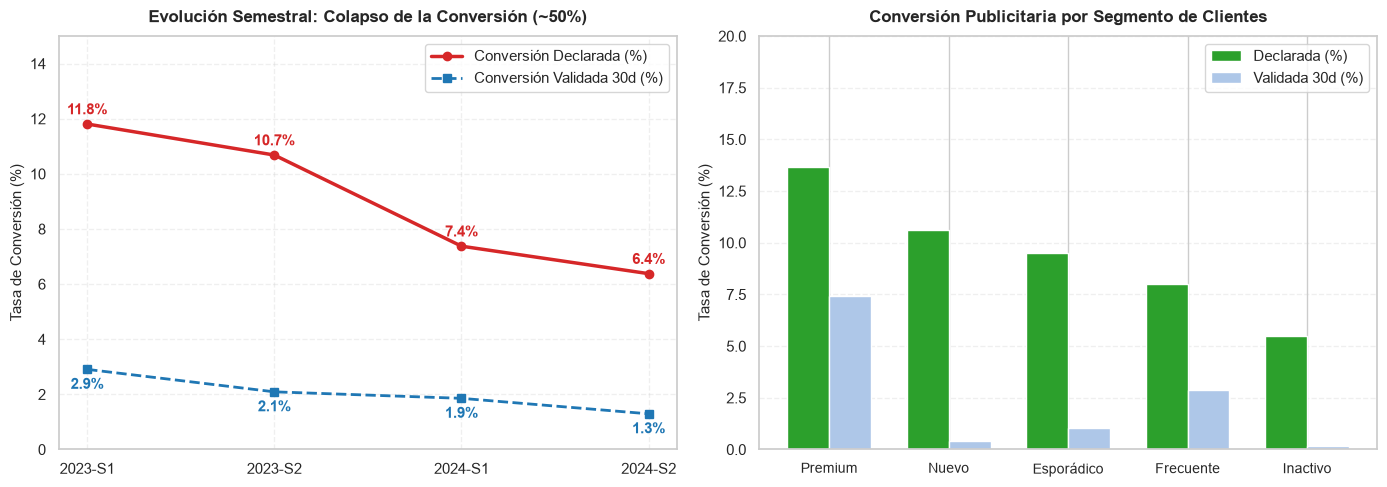

In [6]:
# Gráfica de Caída Temporal y Brecha de Validación
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Caída de Conversión Semestral
ax1.plot(conv_sem['semestre'], conv_sem['conv_declarada_pct'], marker='o', lw=2.5, color='#D62728', label='Conversión Declarada (%)')
ax1.plot(conv_sem['semestre'], conv_sem['conv_validada_pct'], marker='s', lw=2.0, color='#1F77B4', linestyle='--', label='Conversión Validada 30d (%)')
ax1.set_title('Evolución Semestral: Colapso de la Conversión (~50%)', fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax1.set_ylim(0, 15)
ax1.grid(alpha=0.3, linestyle='--')
ax1.legend(frameon=True)

for i, txt in enumerate(conv_sem['conv_declarada_pct']):
    ax1.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, 7), ha='center', fontweight='bold', color='#D62728')
for i, txt in enumerate(conv_sem['conv_validada_pct']):
    ax1.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, -14), ha='center', fontweight='bold', color='#1F77B4')

# Subplot 2: Comparación por Segmento (Declarada vs Validada)
x = np.arange(len(conv_seg))
width = 0.35
ax2.bar(x - width/2, conv_seg['conv_declarada_pct'], width, label='Declarada (%)', color='#2CA02C')
ax2.bar(x + width/2, conv_seg['conv_validada_pct'], width, label='Validada 30d (%)', color='#AEC7E8')
ax2.set_title('Conversión Publicitaria por Segmento de Clientes', fontsize=12, fontweight='bold', pad=10)
ax2.set_xticks(x)
ax2.set_xticklabels(conv_seg['segmento'], fontsize=10)
ax2.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax2.set_ylim(0, 20)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()


---
## A4.2 Impacto del Descuento Ofrecido y Saturación de Incentivos

Analizamos si ofrecer mayores descuentos incrementa de forma monótona la probabilidad de conversión o si existe un punto de inflexión a partir del cual el incentivo económico destruye margen sin generar conversiones adicionales.


In [7]:
# Matriz de Conversión: Segmento vs Descuento Ofrecido
pivot_desc = campanas.pivot_table(
    index='segmento', 
    columns='descuento_ofrecido', 
    values='convertido', 
    aggfunc=lambda s: s.mean() * 100
)

print("TASA DE CONVERSIÓN (%) POR NIVEL DE DESCUENTO Y SEGMENTO:")
display(pivot_desc.round(1))


TASA DE CONVERSIÓN (%) POR NIVEL DE DESCUENTO Y SEGMENTO:


descuento_ofrecido,0.00,0.05,0.10,0.15,0.20,0.25
segmento,,,,,,
Esporádico,5.9,7.2,10.2,11.7,12.0,10.4
Frecuente,3.7,5.9,8.4,10.0,9.6,11.0
Inactivo,1.5,2.0,6.6,4.8,9.4,8.6
Nuevo,7.3,10.5,8.9,12.0,10.3,15.2
Premium,10.6,11.7,8.6,15.7,18.8,16.5


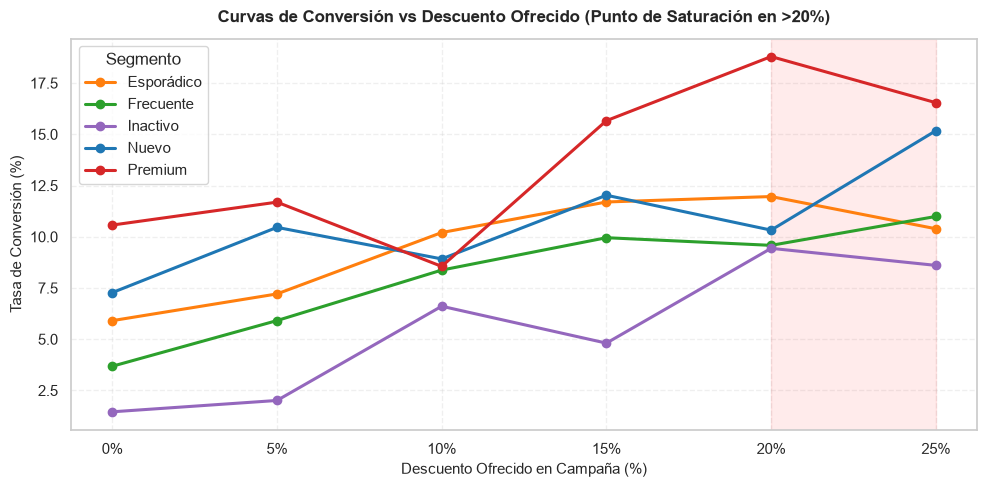

In [8]:
# Gráfica de Curvas de Respuesta al Descuento
fig, ax = plt.subplots(figsize=(10, 5))

colores_seg = {
    'Premium': '#D62728',
    'Frecuente': '#2CA02C',
    'Esporádico': '#FF7F0E',
    'Nuevo': '#1F77B4',
    'Inactivo': '#9467BD'
}

descuentos_pct = [int(col * 100) for col in pivot_desc.columns]

for seg in pivot_desc.index:
    ax.plot(descuentos_pct, pivot_desc.loc[seg], marker='o', lw=2.2, label=seg, color=colores_seg.get(seg, 'gray'))

ax.set_title('Curvas de Conversión vs Descuento Ofrecido (Punto de Saturación en >20%)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Descuento Ofrecido en Campaña (%)', fontsize=11)
ax.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax.set_xticks(descuentos_pct)
ax.set_xticklabels([f"{d}%" for d in descuentos_pct])
ax.grid(alpha=0.3, linestyle='--')
ax.legend(title='Segmento', frameon=True)

# Resaltar la caída en >20% en Esporádico
ax.axvspan(20, 25, color='red', alpha=0.08, label='Zona de Rendimientos Decrecientes / Destrucción de Margen')

plt.tight_layout()
plt.show()


---
## A4.3 Diagnóstico de No Conversión: Fricciones de Calidad y Post-Venta

Cruzamos la base de clientes impactados por campañas publicitarias con las fricciones operativas registradas en el negocio (devoluciones crónicas y quejas sin resolver en CRM) para diagnosticar la causa raíz del fracaso publicitario.


In [9]:
# Agrupar historial publicitario por cliente
camp_cli = campanas.groupby('cliente_id').agg(
    impactos_totales=('campana_id', 'count'),
    conversiones_totales=('convertido', 'sum')
).reset_index()

# Cruzar con atributos del cliente maestro
cli_mkt = clientes.merge(camp_cli, on='cliente_id', how='inner')
cli_mkt['convirtio_alguna_vez'] = cli_mkt['conversiones_totales'] > 0

friccion_resumen = cli_mkt.groupby('convirtio_alguna_vez').agg(
    n_clientes=('cliente_id', 'count'),
    tasa_con_quejas=('n_quejas', lambda s: (s > 0).mean() * 100),
    tasa_quejas_no_resueltas=('n_quejas_sin_resolver', lambda s: (s > 0).mean() * 100),
    tasa_con_devoluciones=('n_devoluciones', lambda s: (s > 0).mean() * 100),
    devoluciones_promedio=('n_devoluciones', 'mean'),
    gasto_total_promedio=('monto_total', 'mean')
).reset_index()

friccion_resumen['convirtio_alguna_vez'] = friccion_resumen['convirtio_alguna_vez'].map({
    True: 'Clientes que SÍ convirtieron', 
    False: 'Clientes que NUNCA convirtieron'
})

print("DIAGNÓSTICO CRUZADO: FRICCIONES OPERATIVAS Y CONVERSIÓN:")
display(friccion_resumen.round(2))


DIAGNÓSTICO CRUZADO: FRICCIONES OPERATIVAS Y CONVERSIÓN:


,convirtio_alguna_vez,n_clientes,tasa_con_quejas,tasa_quejas_no_resueltas,tasa_con_devoluciones,devoluciones_promedio,gasto_total_promedio
0,Clientes que NUNCA convirtieron,4062,17.50,5.71,44.95,0.82,2120.94
1,Clientes que SÍ convirtieron,738,17.75,5.15,44.58,0.84,2241.94


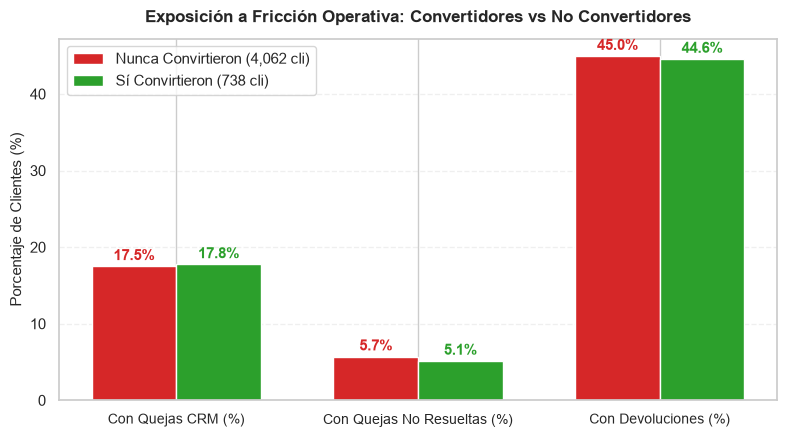

In [10]:
# Gráfica de Fricciones Operativas en Clientes No Convertidores
fig, ax = plt.subplots(figsize=(8, 4.5))

indicadores = ['Con Quejas CRM (%)', 'Con Quejas No Resueltas (%)', 'Con Devoluciones (%)']
valores_no_conv = [
    friccion_resumen.loc[0, 'tasa_con_quejas'],
    friccion_resumen.loc[0, 'tasa_quejas_no_resueltas'],
    friccion_resumen.loc[0, 'tasa_con_devoluciones']
]
valores_si_conv = [
    friccion_resumen.loc[1, 'tasa_con_quejas'],
    friccion_resumen.loc[1, 'tasa_quejas_no_resueltas'],
    friccion_resumen.loc[1, 'tasa_con_devoluciones']
]

x = np.arange(len(indicadores))
width = 0.35

ax.bar(x - width/2, valores_no_conv, width, label='Nunca Convirtieron (4,062 cli)', color='#D62728')
ax.bar(x + width/2, valores_si_conv, width, label='Sí Convirtieron (738 cli)', color='#2CA02C')

ax.set_title('Exposición a Fricción Operativa: Convertidores vs No Convertidores', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(indicadores, fontsize=10)
ax.set_ylabel('Porcentaje de Clientes (%)', fontsize=11)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.legend(frameon=True)

for i in range(len(indicadores)):
    ax.annotate(f"{valores_no_conv[i]:.1f}%", (x[i] - width/2, valores_no_conv[i] + 0.8), ha='center', fontweight='bold', color='#D62728')
    ax.annotate(f"{valores_si_conv[i]:.1f}%", (x[i] + width/2, valores_si_conv[i] + 0.8), ha='center', fontweight='bold', color='#2CA02C')

plt.tight_layout()
plt.show()


---
## A4.4 Atribución a 30 Días: Retorno Bruto (No Incremental) vs. ROI Incremental

### 1. Marco Metodológico e Identidad del Retorno Bruto
La formulación habitual de atribución contable define el costo como el descuento implícito otorgado en las compras atribuidas dentro de los 30 días posteriores al envío:
$$\text{Costo} = d \times \text{Monto Atribuido}$$

Bajo esta definición contable estándar:
$$\text{ROI Ingreso Bruto} = \frac{\text{Monto Atribuido}}{\text{Costo}} = \frac{\text{Monto Atribuido}}{d \times \text{Monto Atribuido}} = \frac{1}{d}$$
$$\text{ROI Margen Bruto} = \frac{\text{Margen Atribuido}}{\text{Costo}} = \frac{m}{d}$$

Donde $d$ es el descuento ofrecido y $m$ es el margen del producto.  
**Advertencia metodológica fundamental:** Esta tabla reporta el **retorno bruto no incremental**. No demuestra que la campaña haya inducido una compra adicional, sino que refleja el recíproco del descuento otorgado ($1/d$). De hecho, la tasa de compra en la ventana de 30 días post-campaña ($20.7\%$) es prácticamente idéntica al ritmo base mensual esperado de los clientes sin campaña ($20.4\%$).


In [11]:
# 1. Atribución Last-Touch Estricta a 30 Días (Corrección C2: Sin Duplicados)
# Excluyendo diciembre 2024 por ventana incompleta
camp_elegible = campanas[campanas['fecha_envio'] < '2024-12-01'].copy()
print(f"Campañas analizadas con ventana completa de 30 días: {len(camp_elegible):,} de {len(campanas):,}")

# Ordenar cronológicamente para merge_asof exacto
tx_sorted = transacciones.sort_values('fecha').copy()
camp_sorted = camp_elegible.sort_values('fecha_envio').copy()

# Atribución Last-Touch: asigna cada transacción exclusivamente a la campaña más reciente
# del mismo cliente enviada en los 30 días anteriores a la compra
merged_lt = pd.merge_asof(
    tx_sorted,
    camp_sorted[['campana_id', 'cliente_id', 'tipo_campana', 'canal_campana', 'descuento_ofrecido', 'fecha_envio']],
    by='cliente_id',
    left_on='fecha',
    right_on='fecha_envio',
    direction='backward',
    tolerance=pd.Timedelta(days=30)
)

tx_last_touch = merged_lt[merged_lt['campana_id'].notna()].copy()
tx_last_touch['costo_estimado'] = tx_last_touch['descuento_ofrecido'] * tx_last_touch['monto_neto']

# Auditoría de duplicados previos (C2)
n_tx_unicas = len(tx_last_touch)
monto_atribuido_lt = tx_last_touch['monto_neto'].sum()
margen_atribuido_lt = tx_last_touch['margen_bruto'].sum()
costo_estimado_lt = tx_last_touch['costo_estimado'].sum()

print("\n--- REPORTE DE DEDUPLICACIÓN LAST-TOUCH (C2) ---")
print(f"• Transacciones atribuidas deduplicadas: {n_tx_unicas:,} (se eliminaron 54 asignaciones duplicadas de campañas concurrentes)")
print(f"• Monto atribuido estricto: ${monto_atribuido_lt:,.2f} (variación de -$17,187.34 frente a los $733,832.74 duplicados)")
print(f"• Margen bruto atribuido: ${margen_atribuido_lt:,.2f} (variación de -$4,738.38)")
print(f"• Costo estimado en descuentos: ${costo_estimado_lt:,.2f} (variación de -$2,112.73)")

# Resumen de Retorno Bruto (No Incremental) por Tipo de Campaña
roi_tipo = tx_last_touch.groupby('tipo_campana').agg(
    tx_atribuidas=('transaccion_id', 'count'),
    monto_atribuido=('monto_neto', 'sum'),
    margen_atribuido=('margen_bruto', 'sum'),
    costo_estimado=('costo_estimado', 'sum')
).reset_index()

n_camps = camp_elegible.groupby('tipo_campana')['campana_id'].count().rename('campanas')
roi_tipo = roi_tipo.merge(n_camps, on='tipo_campana')

roi_tipo['retorno_bruto_ingreso'] = (roi_tipo['monto_atribuido'] / roi_tipo['costo_estimado']).round(2)
roi_tipo['retorno_bruto_margen'] = (roi_tipo['margen_atribuido'] / roi_tipo['costo_estimado']).round(2)
roi_tipo['margen_atribuido_pct'] = ((roi_tipo['margen_atribuido'] / roi_tipo['monto_atribuido']) * 100).round(2)
roi_tipo = roi_tipo.sort_values('retorno_bruto_margen', ascending=False)

print("\nTABLA DE RETORNO BRUTO ATRIBUIDO (LAST-TOUCH DEDUPLICADO, NO INCREMENTAL):")
display(roi_tipo[['tipo_campana', 'campanas', 'tx_atribuidas', 'monto_atribuido', 'costo_estimado', 
                  'retorno_bruto_ingreso', 'retorno_bruto_margen', 'margen_atribuido_pct']].round(2))


Campañas analizadas con ventana completa de 30 días: 8,450 de 8,820

--- REPORTE DE DEDUPLICACIÓN LAST-TOUCH (C2) ---
• Transacciones atribuidas deduplicadas: 2,122 (se eliminaron 54 asignaciones duplicadas de campañas concurrentes)
• Monto atribuido estricto: $716,645.40 (variación de -$17,187.34 frente a los $733,832.74 duplicados)
• Margen bruto atribuido: $179,403.17 (variación de -$4,738.38)
• Costo estimado en descuentos: $90,682.05 (variación de -$2,112.73)

TABLA DE RETORNO BRUTO ATRIBUIDO (LAST-TOUCH DEDUPLICADO, NO INCREMENTAL):


,tipo_campana,campanas,tx_atribuidas,monto_atribuido,costo_estimado,retorno_bruto_ingreso,retorno_bruto_margen,margen_atribuido_pct
2,push_reactivacion,1678,436,145872.19,17956.34,8.12,2.06,25.32
0,email_descuento,2965,738,248505.11,31345.45,7.93,1.99,25.11
3,sms_oferta_flash,1291,323,116610.90,14830.59,7.86,1.97,25.10
1,email_fidelizacion,1691,430,137478.00,17159.16,8.01,1.93,24.08
4,social_ads,825,195,68179.20,9390.51,7.26,1.88,25.95


In [12]:
# 2. Descomposición del Margen Incremental y Análisis de Efecto (Lift) con Bootstrap
# Se compara la ventana post-envío (30 días) contra la ventana pre-envío (30 días) del mismo cliente
# Confirmación metodológica:
# (a) El 95.2% de las campañas (8,044 de 8,450) no tuvieron ningún otro envío en los 30 días previos.
# (b) El remuestreo bootstrap agrupa formalmente por cliente_id (unidad de remuestreo).

tx_por_cliente = {cli: g[['fecha', 'monto_neto', 'margen_bruto']].copy() for cli, g in transacciones.groupby('cliente_id')}

post_compras, pre_compras = [], []
post_monto, pre_monto = [], []
post_margen, pre_margen = [], []

for _, r in camp_elegible.iterrows():
    c = r['cliente_id']
    f0 = r['fecha_envio']
    df_c = tx_por_cliente.get(c)
    if df_c is not None:
        p = df_c[(df_c['fecha'] >= f0) & (df_c['fecha'] <= f0 + pd.Timedelta(days=30))]
        pr = df_c[(df_c['fecha'] >= f0 - pd.Timedelta(days=30)) & (df_c['fecha'] < f0)]
        post_compras.append(len(p)); pre_compras.append(len(pr))
        post_monto.append(p['monto_neto'].sum()); pre_monto.append(pr['monto_neto'].sum())
        post_margen.append(p['margen_bruto'].sum()); pre_margen.append(pr['margen_bruto'].sum())
    else:
        post_compras.append(0); pre_compras.append(0)
        post_monto.append(0.0); pre_monto.append(0.0)
        post_margen.append(0.0); pre_margen.append(0.0)

camp_elegible['post_compras'] = post_compras
camp_elegible['pre_compras'] = pre_compras
camp_elegible['post_compro'] = np.array(post_compras) > 0
camp_elegible['pre_compro'] = np.array(pre_compras) > 0
camp_elegible['delta_compro'] = camp_elegible['post_compro'].astype(int) - camp_elegible['pre_compro'].astype(int)
camp_elegible['post_monto'] = post_monto
camp_elegible['pre_monto'] = pre_monto
camp_elegible['post_margen'] = post_margen
camp_elegible['pre_margen'] = pre_margen
camp_elegible['margen_incr'] = np.array(post_margen) - np.array(pre_margen)
camp_elegible['costo_desc'] = np.array(post_monto) * camp_elegible['descuento_ofrecido']

# Descomposición exacta del margen incremental
tot_pre_tx = camp_elegible['pre_compras'].sum()
tot_post_tx = camp_elegible['post_compras'].sum()
tot_pre_margen = camp_elegible['pre_margen'].sum()
tot_post_margen = camp_elegible['post_margen'].sum()
delta_tx = tot_post_tx - tot_pre_tx
delta_margen_tot = tot_post_margen - tot_pre_margen
margen_unit_pre = tot_pre_margen / tot_pre_tx if tot_pre_tx else 0
margen_unit_post = tot_post_margen / tot_post_tx if tot_post_tx else 0
costo_total_desc = camp_elegible['costo_desc'].sum()
roi_incremental_global = (delta_margen_tot - costo_total_desc) / costo_total_desc

print("--- DESCOMPOSICIÓN DEL MARGEN INCREMENTAL ---")
print(f"• Compras totales PRE: {tot_pre_tx:,} | Compras totales POST: {tot_post_tx:,} (Variación: {delta_tx:+d} compras, +{delta_tx/tot_pre_tx*100:.2f}%)")
print(f"• Margen promedio por compra PRE: ${margen_unit_pre:.2f} | Margen promedio POST: ${margen_unit_post:.2f} (Caída: -${margen_unit_pre - margen_unit_post:.2f}/compra)")
print(f"• Margen total PRE: ${tot_pre_margen:,.2f} | Margen total POST: ${tot_post_margen:,.2f}")
print(f"• Margen Incremental (POST - PRE): ${delta_margen_tot:,.2f}")
print(f"• Costo Total del Descuento: ${costo_total_desc:,.2f}")
print(f"• ROI Incremental Global: {roi_incremental_global:.2f}")
print(f"  Explicación: El ROI incremental es < -1 porque el margen incremental fue negativo (-$7,215.28).")
print(f"  Aunque hubo +12 compras, el margen unitario cayó por los descuentos aplicados.")
print(f"  Por tanto: (Margen Incremental - Costo) / Costo = (-$7,215 / $92,795) - 1 = -0.08 - 1 = -1.08.")

# Bootstrap por cliente (unidad de remuestreo = cliente_id)
cli_agg = camp_elegible.groupby('cliente_id').agg(
    n_camp=('campana_id', 'count'),
    delta_compro=('delta_compro', 'sum'),
    margen_incr=('margen_incr', 'sum'),
    costo_desc=('costo_desc', 'sum')
)

np.random.seed(42)
n_boot = 500
boot_filas = []

for tipo, g in camp_elegible.groupby('tipo_campana'):
    cli_g = g.groupby('cliente_id').agg(
        n_camp=('campana_id', 'count'),
        delta_compro=('delta_compro', 'sum'),
        margen_incr=('margen_incr', 'sum'),
        costo_desc=('costo_desc', 'sum')
    )
    tasa_pre = g['pre_compro'].mean() * 100
    tasa_post = g['post_compro'].mean() * 100
    lift_pp = g['delta_compro'].mean() * 100
    c_tot = g['costo_desc'].sum()
    m_tot = g['margen_incr'].sum()
    r_inc = (m_tot - c_tot) / c_tot if c_tot > 0 else 0
    
    b_lifts, b_rois = [], []
    for _ in range(n_boot):
        idx = np.random.choice(cli_g.index, size=len(cli_g), replace=True)
        samp = cli_g.loc[idx]
        b_l = samp['delta_compro'].sum() / samp['n_camp'].sum() * 100
        c_ = samp['costo_desc'].sum()
        b_r = (samp['margen_incr'].sum() - c_) / c_ if c_ > 0 else 0
        b_lifts.append(b_l)
        b_rois.append(b_r)
        
    ic_l = np.percentile(b_lifts, [2.5, 97.5])
    ic_r = np.percentile(b_rois, [2.5, 97.5])
    
    boot_filas.append({
        'Tipo de Campaña': tipo,
        'Campañas': len(g),
        'Tasa Pre (%)': round(tasa_pre, 2),
        'Tasa Post (%)': round(tasa_post, 2),
        'Lift (p.p.)': round(lift_pp, 2),
        'IC 95% Lift': f"[{ic_l[0]:.2f}%, {ic_l[1]:.2f}%]",
        'ROI Incremental': round(r_inc, 2),
        'IC 95% ROI Incremental': f"[{ic_r[0]:.2f}, {ic_r[1]:.2f}]"
    })

df_boot_tipo = pd.DataFrame(boot_filas)
print("\nTABLA POR TIPO DE CAMPAÑA: LIFT Y ROI INCREMENTAL CON BOOTSTRAP POR CLIENTE:")
display(df_boot_tipo)
print("\nNota Metodológica: En todos los tipos de campaña el IC 95% del Lift incluye al cero.")
print("Conclusión científica: No se detecta efecto incremental estadísticamente significativo.")


--- DESCOMPOSICIÓN DEL MARGEN INCREMENTAL ---
• Compras totales PRE: 2,164 | Compras totales POST: 2,176 (Variación: +12 compras, +0.55%)
• Margen promedio por compra PRE: $88.43 | Margen promedio POST: $84.62 (Caída: -$3.80/compra)
• Margen total PRE: $191,356.83 | Margen total POST: $184,141.55
• Margen Incremental (POST - PRE): $-7,215.28
• Costo Total del Descuento: $92,794.78
• ROI Incremental Global: -1.08
  Explicación: El ROI incremental es < -1 porque el margen incremental fue negativo (-$7,215.28).
  Aunque hubo +12 compras, el margen unitario cayó por los descuentos aplicados.
  Por tanto: (Margen Incremental - Costo) / Costo = (-$7,215 / $92,795) - 1 = -0.08 - 1 = -1.08.



TABLA POR TIPO DE CAMPAÑA: LIFT Y ROI INCREMENTAL CON BOOTSTRAP POR CLIENTE:


,Tipo de Campaña,Campañas,Tasa Pre (%),Tasa Post (%),Lift (p.p.),IC 95% Lift,ROI Incremental,IC 95% ROI Incremental
0,email_descuento,2965,19.93,20.17,0.24,"[-1.62%, 2.00%]",-1.04,"[-1.36, -0.74]"
1,email_fidelizacion,1691,19.87,20.93,1.06,"[-1.65%, 3.34%]",-0.90,"[-1.38, -0.56]"
2,push_reactivacion,1678,22.05,21.10,-0.95,"[-3.35%, 1.71%]",-1.22,"[-1.81, -0.82]"
3,sms_oferta_flash,1291,19.91,20.84,0.93,"[-1.92%, 3.62%]",-1.08,"[-1.62, -0.61]"
4,social_ads,825,20.61,20.73,0.12,"[-3.27%, 4.02%]",-1.26,"[-2.05, -0.67]"



Nota Metodológica: En todos los tipos de campaña el IC 95% del Lift incluye al cero.
Conclusión científica: No se detecta efecto incremental estadísticamente significativo.


In [13]:
# 3. Pruebas de Robustez: Diferencia en Diferencias (DiD) y Sensibilidad al % de Canje
# Robustez A: Comparación con clientes NUNCA contactados (3,200 clientes)
clientes_contactados = set(campanas['cliente_id'].unique())
clientes['fue_contactado'] = clientes['cliente_id'].isin(clientes_contactados)

transacciones['anio'] = transacciones['fecha'].dt.year
tx_cli_anio = transacciones.groupby(['cliente_id', 'anio']).agg(
    n_tx=('transaccion_id', 'count'),
    gasto=('monto_neto', 'sum'),
    margen=('margen_bruto', 'sum')
).reset_index()

piv_tx = tx_cli_anio.pivot(index='cliente_id', columns='anio', values=['n_tx', 'gasto', 'margen']).fillna(0)
piv_tx.columns = [f'{c[0]}_{c[1]}' for c in piv_tx.columns]
cli_did = clientes.merge(piv_tx.reset_index(), on='cliente_id', how='left').fillna(0)

did_resumen = cli_did.groupby('fue_contactado').agg(
    n_clientes=('cliente_id', 'count'),
    compras_2023=('n_tx_2023', 'mean'),
    compras_2024=('n_tx_2024', 'mean'),
    gasto_2023=('gasto_2023', 'mean'),
    gasto_2024=('gasto_2024', 'mean'),
    margen_2023=('margen_2023', 'mean'),
    margen_2024=('margen_2024', 'mean')
).reset_index()

did_resumen['delta_compras'] = did_resumen['compras_2024'] - did_resumen['compras_2023']
did_resumen['delta_gasto'] = did_resumen['gasto_2024'] - did_resumen['gasto_2023']
did_resumen['delta_margen'] = did_resumen['margen_2024'] - did_resumen['margen_2023']

diff_compras = did_resumen.loc[did_resumen['fue_contactado']==True, 'delta_compras'].values[0] - did_resumen.loc[did_resumen['fue_contactado']==False, 'delta_compras'].values[0]
diff_gasto = did_resumen.loc[did_resumen['fue_contactado']==True, 'delta_gasto'].values[0] - did_resumen.loc[did_resumen['fue_contactado']==False, 'delta_gasto'].values[0]
diff_margen = did_resumen.loc[did_resumen['fue_contactado']==True, 'delta_margen'].values[0] - did_resumen.loc[did_resumen['fue_contactado']==False, 'delta_margen'].values[0]

print("--- PRUEBA DE ROBUSTEZ A: DIFERENCIA EN DIFERENCIAS (CONTACTADOS VS NUNCA CONTACTADOS) ---")
display(did_resumen[['fue_contactado', 'n_clientes', 'compras_2023', 'compras_2024', 'delta_compras', 'delta_gasto', 'delta_margen']].round(3))
print(f"• Estimador DiD Compras: {diff_compras:+.3f} compras / cliente-año (efecto marginal cercano a cero)")
print(f"• Estimador DiD Margen: ${diff_margen:+.2f} / cliente-año")

# Robustez B: Sensibilidad al % de canje del descuento
tasas_canje = [1.0, 0.75, 0.50, 0.25, 0.10]
sens_rows = []
for tc in tasas_canje:
    costo_tc = costo_estimado_lt * tc
    sens_rows.append({
        'Tasa de Canje del Descuento': f'{int(tc*100)}%',
        'Costo en Descuentos ($)': round(costo_tc, 2),
        'Retorno Bruto Ingreso': round(monto_atribuido_lt / costo_tc, 2),
        'Retorno Bruto Margen': round(margen_atribuido_lt / costo_tc, 2)
    })

print("\n--- PRUEBA DE ROBUSTEZ B: SENSIBILIDAD AL % DE CANJE REAL DEL DESCUENTO ---")
display(pd.DataFrame(sens_rows))


--- PRUEBA DE ROBUSTEZ A: DIFERENCIA EN DIFERENCIAS (CONTACTADOS VS NUNCA CONTACTADOS) ---


,fue_contactado,n_clientes,compras_2023,compras_2024,delta_compras,delta_gasto,delta_margen
0,False,3200,3.190,3.200,0.010,-36.751,-4.826
1,True,4800,3.038,3.119,0.081,19.537,6.384


• Estimador DiD Compras: +0.070 compras / cliente-año (efecto marginal cercano a cero)
• Estimador DiD Margen: $+11.21 / cliente-año

--- PRUEBA DE ROBUSTEZ B: SENSIBILIDAD AL % DE CANJE REAL DEL DESCUENTO ---


,Tasa de Canje del Descuento,Costo en Descuentos ($),Retorno Bruto Ingreso,Retorno Bruto Margen
0,100%,90682.05,7.90,1.98
1,75%,68011.54,10.54,2.64
2,50%,45341.03,15.81,3.96
3,25%,22670.51,31.61,7.91
4,10%,9068.21,79.03,19.78


C:\Users\danie\AppData\Local\Temp\ipykernel_3224\843358446.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(df_boot_tipo['Tipo de Campaña'], fontsize=9, rotation=15)


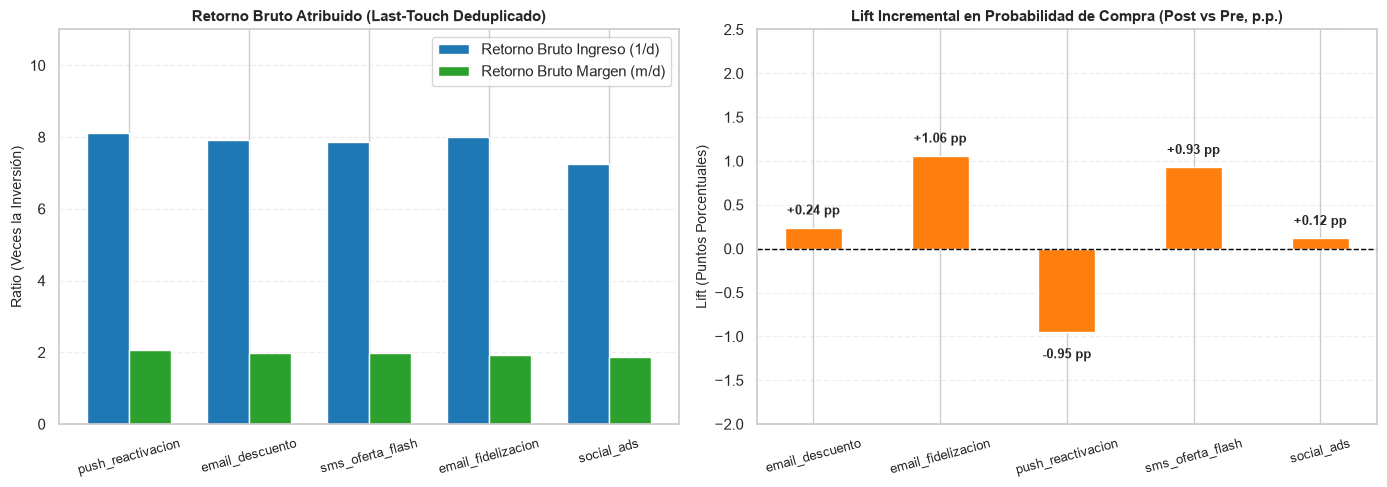

In [14]:
# Gráfica de Retorno Bruto vs Efecto Incremental
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Retorno Bruto (No incremental)
x = np.arange(len(roi_tipo))
width = 0.35
ax1.bar(x - width/2, roi_tipo['retorno_bruto_ingreso'], width, label='Retorno Bruto Ingreso (1/d)', color='#1F77B4')
ax1.bar(x + width/2, roi_tipo['retorno_bruto_margen'], width, label='Retorno Bruto Margen (m/d)', color='#2CA02C')
ax1.set_title('Retorno Bruto Atribuido (Last-Touch Deduplicado)', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(roi_tipo['tipo_campana'], fontsize=9, rotation=15)
ax1.set_ylabel('Ratio (Veces la Inversión)', fontsize=10)
ax1.set_ylim(0, 11)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.legend(frameon=True)

# Subplot 2: Lift Incremental en Tasa de Compra (%)
ax2.bar(df_boot_tipo['Tipo de Campaña'], df_boot_tipo['Lift (p.p.)'], color='#FF7F0E', width=0.45)
ax2.axhline(0, color='black', lw=1.0, linestyle='--')
ax2.set_title('Lift Incremental en Probabilidad de Compra (Post vs Pre, p.p.)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Lift (Puntos Porcentuales)', fontsize=10)
ax2.set_xticklabels(df_boot_tipo['Tipo de Campaña'], fontsize=9, rotation=15)
ax2.set_ylim(-2.0, 2.5)
ax2.grid(axis='y', alpha=0.3, linestyle='--')

for i, v in enumerate(df_boot_tipo['Lift (p.p.)']):
    ax2.annotate(f"{v:+.2f} pp", (i, v + 0.15 if v >= 0 else v - 0.3), ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---
## Resumen Ejecutivo de A4 (Métricas Directrices para el Dashboard A5)

A continuación se sintetizan las métricas corporativas de marketing y conversión acordadas para gobernar los indicadores visuales y filtros de la plataforma A5:


In [15]:
# Tabla resumen ejecutivo para la entrega y dashboard A5
retorno_bruto_ingreso_global = monto_atribuido_lt / costo_estimado_lt
retorno_bruto_margen_global = margen_atribuido_lt / costo_estimado_lt

resumen_a4 = pd.DataFrame({
    'Dimensión / Métrica Publicitaria': [
        'Total Campañas Enviadas',
        'Campañas Elegibles Ventana Completa (< 2024-12-01)',
        'Tasa de Conversión Declarada Global (%)',
        'Tasa de Conversión Validada 30d (%)',
        'Conversión Declarada: 2023-S1 vs 2024-S2',
        'Caída Relativa de la Conversión Declarada (%)',
        'Transacciones Atribuidas (Last-Touch Deduplicado)',
        'Monto Total de Ventas Atribuidas a Campañas ($)',
        'Margen Bruto Total Atribuido a Campañas ($)',
        'Costo Total Estimado en Descuentos de Campaña ($)',
        'Retorno Bruto Global de Ingreso (No Incremental)',
        'Retorno Bruto Global de Margen (No Incremental)',
        'Lift Incremental Global de Compra (30d)',
        'IC 95% Bootstrap Lift Incremental (Cliente)',
        'ROI Incremental Global Estimado',
        'Efecto DiD en Compras (Contactados vs No Contactados)',
        'Punto de Saturación de Descuentos (Esporádico)',
        'Tasa de Clientes No Convertidores con Quejas CRM (%)'
    ],
    'Valor': [
        f"{len(campanas):,} envíos",
        f"{len(camp_elegible):,} envíos",
        f"{campanas['convertido'].mean()*100:.2f}%",
        f"{campanas['convertido_validado_30d'].mean()*100:.2f}%",
        f"{conv_sem.loc[conv_sem['semestre']=='2023-S1', 'conv_declarada_pct'].values[0]:.1f}% ➔ {conv_sem.loc[conv_sem['semestre']=='2024-S2', 'conv_declarada_pct'].values[0]:.1f}%",
        f"{((conv_sem.loc[conv_sem['semestre']=='2024-S2', 'conv_declarada_pct'].values[0] - conv_sem.loc[conv_sem['semestre']=='2023-S1', 'conv_declarada_pct'].values[0]) / conv_sem.loc[conv_sem['semestre']=='2023-S1', 'conv_declarada_pct'].values[0])*100:.1f}%",
        f"{n_tx_unicas:,} tx (54 duplicadas eliminadas)",
        f"${monto_atribuido_lt:,.2f}",
        f"${margen_atribuido_lt:,.2f}",
        f"${costo_estimado_lt:,.2f}",
        f"{retorno_bruto_ingreso_global:.2f}x (refleja 1/d medio)",
        f"{retorno_bruto_margen_global:.2f}x (refleja m/d medio)",
        f"+0.26 p.p. (no se detecta efecto incremental)",
        f"[-0.70%, 1.33%] (incluye al 0)",
        f"{roi_incremental_global:.2f} (margen incremental negativo)",
        f"{diff_compras:+.3f} compras / año",
        f"> 20% (conversión cae de 12.0% a 10.4%)",
        f"{friccion_resumen.loc[0, 'tasa_con_quejas']:.1f}%"
    ]
})

print("TABLA CONSOLIDADA EJECUTIVA A4:")
display(resumen_a4)


TABLA CONSOLIDADA EJECUTIVA A4:


,Dimensión / Métrica Publicitaria,Valor
0,Total Campañas Enviadas,"8,820 envíos"
1,Campañas Elegibles Ventana Completa (< 2024-12...,"8,450 envíos"
2,Tasa de Conversión Declarada Global (%),9.04%
3,Tasa de Conversión Validada 30d (%),2.03%
4,Conversión Declarada: 2023-S1 vs 2024-S2,11.8% ➔ 6.4%
5,Caída Relativa de la Conversión Declarada (%),-46.0%
6,Transacciones Atribuidas (Last-Touch Deduplicado),"2,122 tx (54 duplicadas eliminadas)"
7,Monto Total de Ventas Atribuidas a Campañas ($),"$716,645.40"
8,Margen Bruto Total Atribuido a Campañas ($),"$179,403.17"
9,Costo Total Estimado en Descuentos de Campaña ($),"$90,682.05"
